In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Advanced classifiers
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)

# Hyperparameter tuning with group-aware cross-validation
from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedGroupKFold
)

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# Feature importance
from sklearn.inspection import permutation_importance

# Save trained models
import joblib

In [37]:
df=pd.read_csv("blackout.csv")

In [38]:
X=df.drop(columns=["blackout"])
y=df["blackout"]

In [39]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [40]:
pipeline=Pipeline([("scaler",StandardScaler()),('model',RandomForestClassifier())])

In [54]:
param_grid={"model__n_estimators":[2,4,6],"model__max_depth":[4,8,11,None],"model__min_samples_split":[2,4,6],"model__min_samples_leaf":[2,3,5,7],"model__max_features":[200,30,100,225],"model__class_weight":[None,"balanced"]}

In [55]:
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


In [56]:
import pandas as pd

# Identify the bus columns
bus_columns = [
    column for column in X_train.columns
    if column.startswith("bus_")
]

# Identical bus configurations receive the same group identifier
groups_train = pd.util.hash_pandas_object(
    X_train[bus_columns],
    index=False
).to_numpy()
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="recall",
    cv=cv,
    n_jobs=-1
)


In [57]:
grid_search.set_params(param_grid=param_grid)

grid_search.fit(
    X_train,
    y_train,
    groups=groups_train
)

print("Best parameters:", grid_search.best_params_)
print("Best mean CV recall", grid_search.best_score_)

best_knn = grid_search.best_estimator_

Best parameters: {'model__class_weight': 'balanced', 'model__max_depth': 11, 'model__max_features': 200, 'model__min_samples_leaf': 2, 'model__min_samples_split': 6, 'model__n_estimators': 6}
Best mean CV recall 0.9744803668627948


In [58]:
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

# Retrieve the Random Forest from the completed GridSearch
best_estimator = grid_search.best_estimator_

if hasattr(best_estimator, "named_steps"):
    best_rf = best_estimator.named_steps["model"]
else:
    best_rf = best_estimator

if not isinstance(best_rf, RandomForestClassifier):
    raise TypeError("The GridSearch must contain a RandomForestClassifier.")

rf_params = best_rf.get_params()

# Reference: keep all input features
feature_sets = {
    "All features": X_train.columns.tolist()
}

# Identify nonconstant features using training data only
variable_columns = X_train.columns[
    X_train.nunique() > 1
].tolist()

In [63]:
import numpy as np
from sklearn.model_selection import GroupShuffleSplit

# Keep a copy of the current training data
X_pool = X_train.copy()
y_pool = y_train.copy()
groups_pool = np.asarray(groups_train)

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(X_pool, y_pool, groups=groups_pool)
)

# New training set
X_train = X_pool.iloc[train_idx].copy()
y_train = y_pool.iloc[train_idx].copy()
groups_train = groups_pool[train_idx]

# Validation set
X_val = X_pool.iloc[val_idx].copy()
y_val = y_pool.iloc[val_idx].copy()

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Validation classes:")
print(y_val.value_counts(normalize=True))

Train: (11897, 224)
Validation: (2966, 224)
Validation classes:
blackout
0    0.802765
1    0.197235
Name: proportion, dtype: float64


In [64]:
filter_selector = SelectKBest(
    score_func=f_classif,
    k=min(50, len(variable_columns))
)

filter_selector.fit(
    X_train[variable_columns],
    y_train
)

feature_sets["Filter"] = np.array(variable_columns)[
    filter_selector.get_support()
].tolist()

print("Filter - selected features:", len(feature_sets["Filter"]))

Filter - selected features: 50


In [65]:
correlations = (
    X_train[variable_columns]
    .corr()
    .abs()
    .fillna(0)
)

kept_columns = []

for column in variable_columns:
    if not kept_columns:
        kept_columns.append(column)

    elif (correlations.loc[column, kept_columns] <= 0.95).all():
        kept_columns.append(column)

feature_sets["Redundancy"] = kept_columns

print("Redundancy - selected features:", len(kept_columns))

Redundancy - selected features: 125


In [66]:
scaler_l1 = StandardScaler()

X_train_scaled = scaler_l1.fit_transform(
    X_train[variable_columns]
)

l1_selector = LogisticRegression(
    penalty="l1",
    solver="liblinear",
    C=0.1,
    class_weight="balanced",
    max_iter=5000,
    random_state=42
)

l1_selector.fit(X_train_scaled, y_train)

selected_mask = np.abs(l1_selector.coef_[0]) > 1e-6

feature_sets["Logistic L1"] = np.array(variable_columns)[
    selected_mask
].tolist()

print("L1 - selected features:", len(feature_sets["Logistic L1"]))

C:\Users\anais\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\anais\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


L1 - selected features: 97


In [67]:
results = []
trained_models = {}

for method, columns in feature_sets.items():

    if not columns:
        print(f"{method}: no feature selected. Try a larger C for L1.")
        continue

    # Same Random Forest settings for every feature subset
    model = RandomForestClassifier(**rf_params)

    model.fit(
        X_train[columns],
        y_train
    )

    predictions = model.predict(X_val[columns])

    trained_models[method] = model

    results.append({
        "Method": method,
        "Features": len(columns),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, predictions, zero_division=0
        )
    })

comparison = (
    pd.DataFrame(results)
    .sort_values("F1-score", ascending=False)
    .reset_index(drop=True)
)

display(comparison.round(4))

,Method,Features,Precision,Recall,F1-score
0,Redundancy,125,0.8092,0.9573,0.8771
1,All features,224,0.7917,0.9744,0.8736
2,Logistic L1,97,0.8035,0.9504,0.8708
3,Filter,50,0.7271,0.8974,0.8034


In [68]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold

gb_model = GradientBoostingClassifier(
    min_samples_leaf=5,
    random_state=42
)

gb_param_grid = {
    "n_estimators": [100, 200],
    "learning_rate": [0.05, 0.1],
    "max_depth": [2, 3]
}

gb_cv = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

gb_grid_search = GridSearchCV(
    estimator=gb_model,
    param_grid=gb_param_grid,
    scoring={
        "recall": "recall",
        "precision": "precision",
        "f1": "f1"
    },
    refit="recall",
    cv=gb_cv,
    n_jobs=-1,
    error_score="raise"
)

gb_grid_search.fit(
    X_train,
    y_train,
    groups=groups_train
)

print("Best parameters:", gb_grid_search.best_params_)
print("Best mean CV recall:", gb_grid_search.best_score_)

Best parameters: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200}
Best mean CV recall: 0.9331443465092194


In [73]:
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score

# Store the features selected by each method
gb_feature_sets = {
    "All features": X_train.columns.tolist()
}

# Exclude constant features from feature selection
variable_columns = X_train.columns[
    X_train.nunique() > 1
].tolist()

In [75]:
from sklearn.base import clone
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

gb_results = []
gb_trained_models = {}

for method, columns in feature_sets.items():

    # Use the best Gradient Boosting parameters
    model = clone(gb_grid_search.best_estimator_)

    # Train using the features selected by this method
    model.fit(X_train[columns], y_train)

    predictions = model.predict(X_val[columns])

    gb_trained_models[method] = model

    gb_results.append({
        "Method": method,
        "Features": len(columns),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, predictions, zero_division=0
        )
    })

# Prioritize recall, then precision
gb_comparison = (
    pd.DataFrame(gb_results)
    .sort_values(
        ["Recall", "Precision"],
        ascending=False
    )
    .reset_index(drop=True)
)

display(gb_comparison.round(4))

,Method,Features,Precision,Recall,F1-score
0,Redundancy,125,0.9946,0.9385,0.9657
1,All features,224,0.9927,0.9282,0.9594
2,Logistic L1,97,0.9781,0.9145,0.9452
3,Filter,50,0.8853,0.8051,0.8433


In [84]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Retrieve the trained model and its selected features
from sklearn.base import clone

# Features selected during the redundancy step
columns = redundancy_columns

# Reuse the best parameters found by GridSearch
gb_redundancy = clone(gb_grid_search.best_estimator_)

gb_redundancy.fit(
    X_train[columns],
    y_train
)
# Probability of class 1: blackout
positive_index = list(gb_redundancy.classes_).index(1)

probabilities = gb_redundancy.predict_proba(
    X_val[columns]
)[:, positive_index]

threshold_results = []

for threshold in np.round(np.arange(0.05, 0.55, 0.05), 2):

    predictions = (probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        predictions,
        labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, predictions, zero_division=0
        ),
        "False positives": fp,
        "False negatives": fn
    })

gb_threshold_comparison = pd.DataFrame(threshold_results)

display(gb_threshold_comparison.round(4))

,Threshold,Precision,Recall,F1-score,False positives,False negatives
0,0.05,0.5509,0.9897,0.7078,472,6
1,0.10,0.6830,0.9761,0.8037,265,14
2,0.15,0.7752,0.9726,0.8628,165,16
3,0.20,0.8324,0.9675,0.8949,114,19
4,0.25,0.8733,0.9658,0.9172,82,20
5,0.30,0.9142,0.9658,0.9393,53,20
6,0.35,0.9369,0.9641,0.9503,38,21
7,0.40,0.9674,0.9624,0.9649,19,22
8,0.45,0.9754,0.9470,0.9610,14,31
9,0.50,0.9946,0.9385,0.9657,3,36


,Importance
line_5_reactive_power_flow,0.275440
line_10_reactive_power_flow,0.100745
line_10_active_power_flow,0.039490
line_9_reactive_power_flow,0.036565
line_7_active_power_flow,0.032392
line_11_active_power_flow,0.025346
line_32_reactive_power_flow,0.022557
line_27_active_power_flow,0.018242
line_8_reactive_power_flow,0.017547
line_31_reactive_power_flow,0.017514


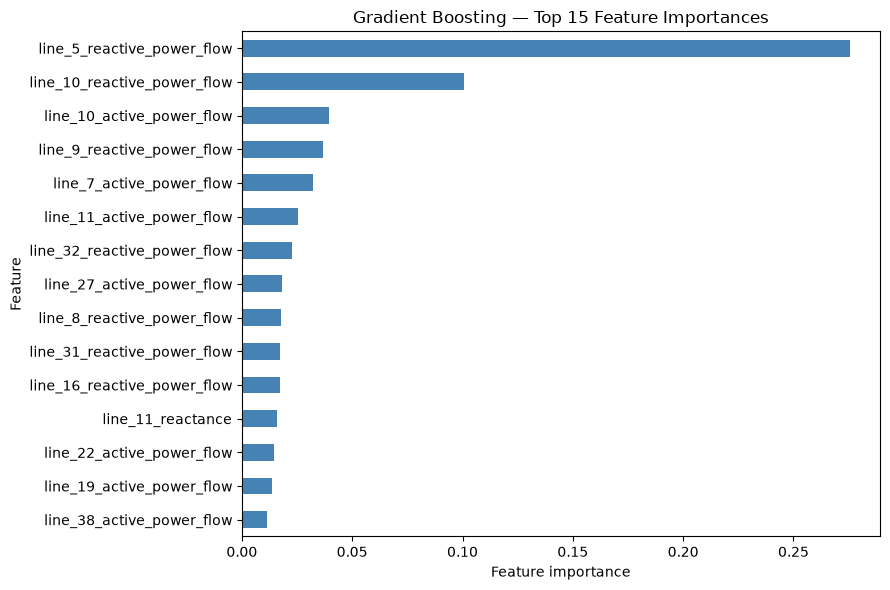

In [85]:
import pandas as pd
import matplotlib.pyplot as plt

# Match each importance with the feature used during training
gb_importances = pd.Series(
    gb_redundancy.feature_importances_,
    index=gb_redundancy.feature_names_in_,
    name="Importance"
).sort_values(ascending=False)

# Display the 15 most important features
display(gb_importances.head(15).to_frame())

# Plot their importance
gb_importances.head(15).sort_values().plot.barh(
    figsize=(9, 6),
    color="steelblue"
)

plt.title("Gradient Boosting — Top 15 Feature Importances")
plt.xlabel("Feature importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [86]:
import numpy as np
import pandas as pd

# Random Forest with all features
rf_candidate = comparison.loc[
    comparison["Method"] == "All features"
].iloc[0]

# Gradient Boosting with Redundancy and threshold 0.30
gb_candidate = gb_threshold_comparison.loc[
    np.isclose(gb_threshold_comparison["Threshold"], 0.30)
].iloc[0]

final_candidates = pd.DataFrame([
    {
        "Model": "Random Forest",
        "Selection": "All features",
        "Threshold": 0.50,
        "Features": int(rf_candidate["Features"]),
        "Precision": rf_candidate["Precision"],
        "Recall": rf_candidate["Recall"],
        "F1-score": rf_candidate["F1-score"]
    },
    {
        "Model": "Gradient Boosting",
        "Selection": "Redundancy",
        "Threshold": 0.30,
        "Features": gb_redundancy.n_features_in_,
        "Precision": gb_candidate["Precision"],
        "Recall": gb_candidate["Recall"],
        "F1-score": gb_candidate["F1-score"]
    }
])

display(final_candidates.round(4))

,Model,Selection,Threshold,Features,Precision,Recall,F1-score
0,Random Forest,All features,0.5,224,0.7917,0.9744,0.8736
1,Gradient Boosting,Redundancy,0.3,125,0.9142,0.9658,0.9393


In [90]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

rf_model = trained_models["All features"]

positive_index = list(rf_model.classes_).index(1)

rf_probabilities = rf_model.predict_proba(
    X_val[X_train.columns]
)[:, positive_index]

rf_threshold_results = []

for threshold in np.round(np.arange(0.05, 0.55, 0.05), 2):

    predictions = (
        rf_probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=[0, 1]
    ).ravel()

    rf_threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, predictions, zero_division=0
        ),
        "False positives": fp,
        "False negatives": fn
    })

rf_threshold_comparison = pd.DataFrame(
    rf_threshold_results
)

display(rf_threshold_comparison.round(4))

,Threshold,Precision,Recall,F1-score,False positives,False negatives
0,0.05,0.5843,0.9829,0.7330,409,10
1,0.10,0.6139,0.9812,0.7553,361,11
2,0.15,0.6457,0.9812,0.7788,315,11
3,0.20,0.6862,0.9795,0.8070,262,12
4,0.25,0.7136,0.9795,0.8256,230,12
5,0.30,0.7315,0.9778,0.8369,210,13
6,0.35,0.7493,0.9761,0.8478,191,14
7,0.40,0.7634,0.9761,0.8567,177,14
8,0.45,0.7706,0.9761,0.8612,170,14
9,0.50,0.7917,0.9744,0.8736,150,15


In [91]:
from sklearn.metrics import precision_score, recall_score

rf_checks = []

models_to_check = {
    "RF du tableau initial": trained_models["All features"],
    "RF du GridSearch": grid_search.best_estimator_
}

for name, model in models_to_check.items():

    predictions = model.predict(X_val[X_train.columns])

    rf_checks.append({
        "Model": name,
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        )
    })

display(pd.DataFrame(rf_checks).round(4))

,Model,Precision,Recall
0,RF du tableau initial,0.7917,0.9744
1,RF du GridSearch,0.7964,0.9761


In [ ]:
"""Nous avons retenu le modèle Random Forest avec l’ensemble des variables et un seuil de décision de 0,50. Sur le jeu de validation,
il atteint un recall de 97,44 % et une précision de 79,17 %, avec 15 cas de blackout manqués et 150 fausses alertes. Le recall reste
notre priorité, mais abaisser le seuil à 0,15 permettrait de détecter seulement quatre cas supplémentaires, tout en générant 165 fausses
alertes supplémentaires. Nous conservons donc le seuil de 0,50, qui offre un compromis satisfaisant entre la détection des blackouts et la
limitation des fausses alertes. Ce choix sera ensuite évalué sur le jeu de test réservé."""